# Time Series Forecasting on the Avocado Dataset

This notebook uses the actual avocado CSV file and converts it into a monthly sales series for modeling with Auto Regression, ARMA, ARIMA, and SARIMA.

In [10]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX


In [11]:
data_path = Path("avocado_dataset.csv")
if not data_path.is_file():
    data_path = Path("avocado.csv") / "avocado.csv"
if not data_path.is_file():
    data_path = Path("avocado.csv")

if not data_path.is_file():
    raise FileNotFoundError(f"Avocado CSV not found: {data_path.resolve()}")

df = pd.read_csv(data_path)
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").copy()

df = df[df["region"].eq("Albany")]
df = df[df["type"].eq("conventional")]

series = df.resample("MS", on="Date")["Total Volume"].sum().asfreq("MS").fillna(0)
series.head()


Date
2015-01-01    171727.14
2015-02-01    209370.24
2015-03-01    253294.82
2015-04-01    194376.61
2015-05-01    486077.58
Freq: MS, Name: Total Volume, dtype: float64

## Train/Test Split

The notebook uses the last 20% of the monthly series for testing.

In [12]:
train_size = int(len(series) * 0.8)
train = series.iloc[:train_size]
test = series.iloc[train_size:]

train.tail(), test.head()


(Date
 2017-03-01    418793.80
 2017-04-01    502797.76
 2017-05-01    446069.89
 2017-06-01    363174.61
 2017-07-01    470091.66
 Freq: MS, Name: Total Volume, dtype: float64,
 Date
 2017-08-01    376100.47
 2017-09-01    322592.45
 2017-10-01    339284.93
 2017-11-01    344912.94
 2017-12-01    493526.60
 Freq: MS, Name: Total Volume, dtype: float64)

## 1) Auto Regression

In [13]:
lags = 12
ar_model = AutoReg(train, lags=lags, trend="t")
ar_fit = ar_model.fit()
ar_forecast = ar_fit.forecast(steps=len(test))
ar_forecast.head()


2017-08-01    189833.969169
2017-09-01    299517.119282
2017-10-01    168008.018491
2017-11-01      7010.831376
2017-12-01    137935.808850
Freq: MS, dtype: float64

## 2) ARMA

In [14]:
arma_model = ARIMA(train, order=(1, 0, 1), enforce_stationarity=False, enforce_invertibility=False)
arma_fit = arma_model.fit()
arma_forecast = arma_fit.forecast(steps=len(test))
arma_fit.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:           Total Volume   No. Observations:                   31
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -372.862
Date:                Wed, 18 Nov 2026   AIC                            753.725
Time:                        00:58:51   BIC                            759.194
Sample:                    01-01-2015   HQIC                           755.437
                         - 07-01-2017                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       3.979e+05   2.28e+04     17.484      0.000    3.53e+05    4.42e+05
ar.L1          0.6480      0.201      3.222      0.001       0.254       1.042
ma.L1         -0.5510      0.326     -1.690      0.091      -1.190       0.088
sigma2      8.228e+09      0.106    7.8e+10      0.000    8.23e+09    8.23e+09
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 0.45
Prob(Q):                              0.99   Prob(JB):                         0.80
Heteroskedasticity (H):               1.03   Skew:                             0.17
Prob(H) (two-sided):                  0.97   Kurtosis:                         2.50
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 2.98e+26. Standard errors may be unstable.
"""

## 3) ARIMA

In [15]:
arima_model = ARIMA(train, order=(2, 1, 1), enforce_stationarity=False, enforce_invertibility=False)
arima_fit = arima_model.fit()
arima_forecast = arima_fit.forecast(steps=len(test))
arima_fit.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:           Total Volume   No. Observations:                   31
Model:                 ARIMA(2, 1, 1)   Log Likelihood                -361.245
Date:                Wed, 18 Nov 2026   AIC                            730.491
Time:                        00:58:51   BIC                            735.819
Sample:                    01-01-2015   HQIC                           732.120
                         - 07-01-2017                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4593      0.295      1.559      0.119      -0.118       1.037
ar.L2          0.3261      0.321      1.015      0.310      -0.304       0.956
ma.L1         -1.1410      0.192     -5.949      0.000      -1.517      -0.765
sigma2      1.022e+10   1.03e-11   9.96e+20      0.000    1.02e+10    1.02e+10
===================================================================================
Ljung-Box (L1) (Q):                   0.83   Jarque-Bera (JB):                 2.50
Prob(Q):                              0.36   Prob(JB):                         0.29
Heteroskedasticity (H):               1.00   Skew:                             0.73
Prob(H) (two-sided):                  1.00   Kurtosis:                         2.81
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 1.66e+37. Standard errors may be unstable.
"""

## 4) SARIMA

In [16]:
sarima_model = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 0, 1, 12),
                     enforce_stationarity=False, enforce_invertibility=False)
sarima_fit = sarima_model.fit(disp=False)
sarima_forecast = sarima_fit.forecast(steps=len(test))
sarima_fit.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                       Total Volume   No. Observations:                   31
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 12)   Log Likelihood                -203.368
Date:                            Wed, 18 Nov 2026   AIC                            416.737
Time:                                    00:58:51   BIC                            420.599
Sample:                                01-01-2015   HQIC                           416.934
                                     - 07-01-2017                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1307      0.654     -0.200      0.842      -1.413       1.152
ma.L1         -0.4512      0.918     -0.491      0.623      -2.251       1.349
ar.S.L12      -0.8510      1.369     -0.621      0.534      -3.535       1.833
ma.S.L12       1.3564      1.324      1.024      0.306      -1.239       3.952
sigma2      1.021e+10   1.95e-10   5.24e+19      0.000    1.02e+10    1.02e+10
===================================================================================
Ljung-Box (L1) (Q):                   0.44   Jarque-Bera (JB):                 1.60
Prob(Q):                              0.51   Prob(JB):                         0.45
Heteroskedasticity (H):               0.60   Skew:                            -0.77
Prob(H) (two-sided):                  0.59   Kurtosis:                         2.87
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 5.49e+36. Standard errors may be unstable.
"""

In [17]:
def forecast_metrics(name, actual, forecast):
    rmse = np.sqrt(mean_squared_error(actual, forecast))
    mape = np.mean(np.abs((actual - forecast) / actual)) * 100
    return {"Model": name, "RMSE": round(float(rmse), 3), "MAPE (%)": round(float(mape), 3)}

results = [
    forecast_metrics("Auto Regression", test.values, ar_forecast.values),
    forecast_metrics("ARMA (1, 0, 1)", test.values, arma_forecast.values),
    forecast_metrics("ARIMA (2, 1, 1)", test.values, arima_forecast.values),
    forecast_metrics("SARIMA (1, 1, 1) x (1, 0, 1, 12)", test.values, sarima_forecast.values),
]
pd.DataFrame(results)


,Model,RMSE,MAPE (%)
0,Auto Regression,286791.752,59.042
1,"ARMA (1, 0, 1)",86978.033,17.885
2,"ARIMA (2, 1, 1)",85019.889,19.697
3,"SARIMA (1, 1, 1) x (1, 0, 1, 12)",139337.708,26.757


## Visualize the Forecast

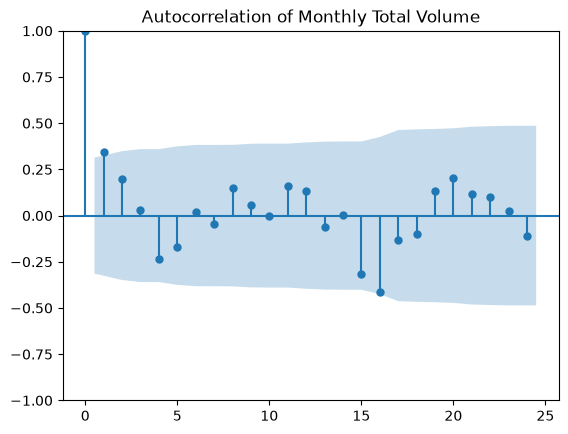

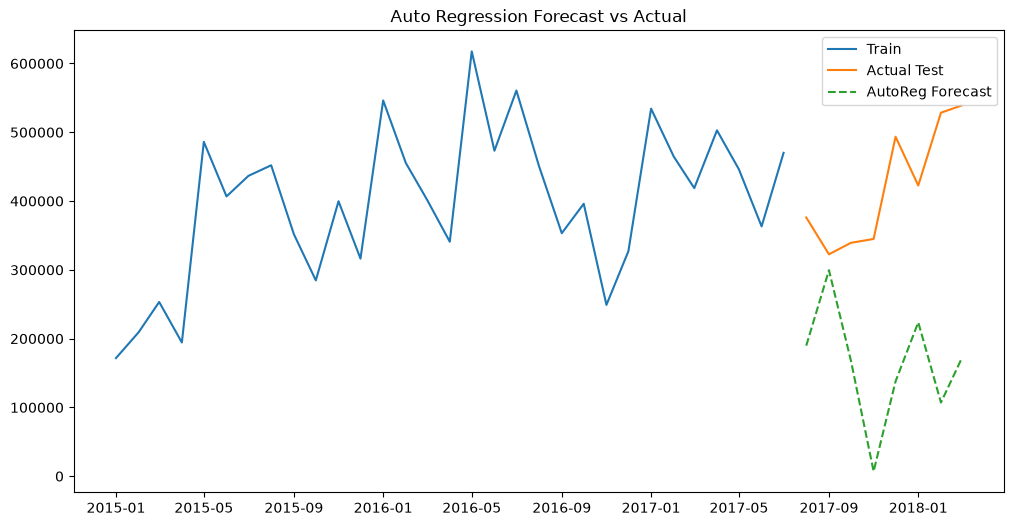

In [18]:
plot_acf(series, lags=24)
plt.title("Autocorrelation of Monthly Total Volume")
plt.show()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(train.index, train.values, label="Train")
ax.plot(test.index, test.values, label="Actual Test")
ax.plot(test.index, ar_forecast.values, label="AutoReg Forecast", linestyle="--")
ax.set_title("Auto Regression Forecast vs Actual")
ax.legend()
plt.show()
